# Module 05 — ResNet (residual connections · batch normalization · the degradation problem)

AlexNet (Module 04) had eight layers. In 2014 VGG went to nineteen and got better, and
Google's GoogLeNet to twenty-two. Then the trend broke: stack still more layers on a plain
network and it gets *worse* — not on the test set, which would be overfitting, but on its own
**training data**. A deeper network can always copy a shallower one (let the extra layers
compute the identity), so this is not a lack of capacity; gradient descent simply fails to
find a solution that exists. In December 2015 He, Zhang, Ren & Sun fixed it with one addition
per block — $y = \mathrm{relu}(\mathcal{F}(x) + x)$ — and trained 152 layers.

This notebook builds that fix and the tool that made it work. **Batch normalization**,
**residual blocks** (with the **zero-padding shortcut** for blocks that change shape),
**global average pooling** and **bias-free layers** join `nanograd` in both languages. We
reproduce the degradation problem on a toy — 128 points and a 34-layer network — measure
*why* it happens, fix it, then train the paper's CIFAR-10 ResNets, redo its Figure 6, delete
blocks from a trained network to see what a ResNet really is, and close by cross-checking
against PyTorch, TensorFlow and Keras.

In [1]:
import os, sys, math, time
# Windows + conda: conda's MKL (via LLVM OpenMP) and pip's PyTorch each bring
# an OpenMP runtime, and two in one process crash whichever loads first.
# Running MKL single-threaded keeps it from loading one at all; the heavy
# CIFAR training here is cached, so the cost is small. (A no-op wherever
# NumPy uses OpenBLAS instead of MKL.)
os.environ.setdefault('MKL_THREADING_LAYER', 'SEQUENTIAL')
import numpy as np
import matplotlib.pyplot as plt

# Locate the repo root whether Jupyter was launched from it or the module folder.
def _find_repo():
    here = os.getcwd()
    cands = [here] + [os.path.abspath(os.path.join(here, *(['..'] * k))) for k in range(1, 6)]
    for base in cands:
        if os.path.isdir(os.path.join(base, 'lib', 'python', 'nanograd')):
            return base
    return here

REPO = _find_repo()
TOPIC = os.path.join(REPO, 'topics', '05-resnet')
sys.path.insert(0, os.path.join(REPO, 'lib', 'python'))   # nanograd
sys.path.insert(0, os.path.join(TOPIC, 'python'))          # canonical resnet.py
sys.path.insert(0, os.path.join(TOPIC, 'tests'))           # check_utils
sys.path.insert(0, os.path.join(REPO, 'data'))             # get_cifar10

import nanograd as ng
import resnet as canon
from nanograd.rng import Rng
from check_utils import rel_error, eval_numerical_gradient, eval_numerical_gradient_array
np.set_printoptions(precision=4, suppress=True)
print('new in nanograd:', ['BatchNorm', 'Residual', 'ZeroPadShortcut', 'GlobalAvgPool2D'],
      '+ Linear/Conv2D(bias=False), Sequential.buffers(), Conv2D(cache_cols, workers)')

new in nanograd: ['BatchNorm', 'Residual', 'ZeroPadShortcut', 'GlobalAvgPool2D'] + Linear/Conv2D(bias=False), Sequential.buffers(), Conv2D(cache_cols, workers)


## 1. The toy: deep spirals

Two spirals, one per class, wound one and a half times around each other: 128 points. A
small network separates them easily — which is the point. We will ask a **34-layer** one to
do it: a stem (`Linear` + ReLU), sixteen **blocks** of
`Linear → BatchNorm → ReLU → Linear → BatchNorm → ReLU`, and a head. Its **residual twin**
has the same layers and starts from the same weights; each of its blocks adds its input back
just before the last ReLU. Nothing else differs. Training is full-batch SGD with momentum —
so BatchNorm's batch statistics are the whole data set's — and `c/resnet.c` regenerates
exactly these points, these weights and these 400 steps.

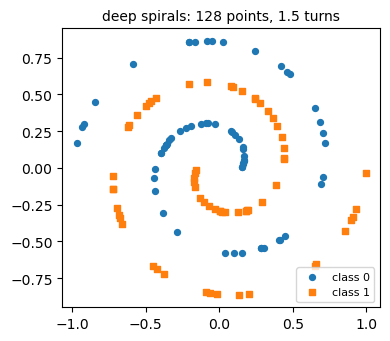

34 weight layers, 9,298 parameters; one block:
   ['Linear', 'BatchNorm', 'ReLU', 'Linear', 'BatchNorm'] + shortcut -> ReLU


In [2]:
X, y = canon.make_spirals()
fig, ax = plt.subplots(figsize=(4, 4))
for c, mk in ((0, 'o'), (1, 's')):
    ax.scatter(X[y == c, 0], X[y == c, 1], marker=mk, s=18, label=f'class {c}')
ax.set_aspect('equal'); ax.legend(loc='lower right', fontsize=8)
ax.set_title('deep spirals: 128 points, 1.5 turns', fontsize=10)
plt.tight_layout(); plt.show()
net = canon.build_toy_net(canon.DEPTH, residual=True)
print(f'{canon.n_layers(net)} weight layers, {canon.n_params(net):,} parameters; one block:')
print('  ', [type(l).__name__ for l in net.layers[2].body.layers], '+ shortcut -> ReLU')

## 2. The degradation problem, in miniature

Plain networks of 4 to 66 layers, the same 128 points, the same recipe — 400 full-batch SGD
steps, BatchNorm in every block, He initialization — five seeds each. Nothing about the
problem changes with depth, and a deeper network can represent everything a shallower one
can: give its extra blocks weights that compute the identity and it *is* the shallower
network. So if depth only ever helped, or merely didn't hurt, the deeper networks would fit
these points at least as well.

plain  4 layers: train acc mean 1.000  min 1.000   final loss 0.0007


plain  6 layers: train acc mean 1.000  min 1.000   final loss 0.0003


plain 10 layers: train acc mean 1.000  min 1.000   final loss 0.0003


plain 18 layers: train acc mean 1.000  min 1.000   final loss 0.0004


plain 34 layers: train acc mean 0.644  min 0.531   final loss 0.4656


plain 66 layers: train acc mean 0.522  min 0.469   final loss 0.4856
(164s)


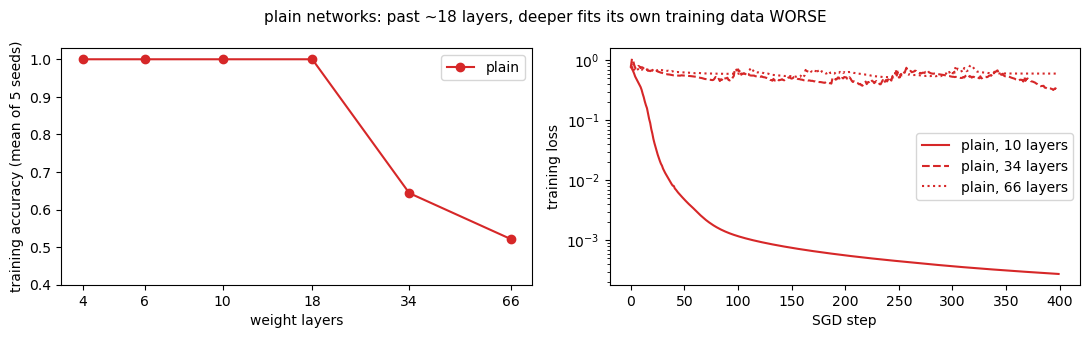

In [3]:
DEPTHS = (1, 2, 4, 8, 16, 32)          # blocks -> 2*D + 2 = 4 ... 66 layers
SEEDS = range(5)
t0 = time.time()
sweep = {False: {}, True: {}}
for D in DEPTHS:
    sweep[False][D] = [canon.train_toy_vectorized(D, residual=False, seed=s) for s in SEEDS]
    accs = [r['acc'] for r in sweep[False][D]]
    print(f'plain {2 * D + 2:2d} layers: train acc mean {np.mean(accs):.3f}  min {np.min(accs):.3f}   '
          f'final loss {np.mean([r["loss"][-1] for r in sweep[False][D]]):.4f}')
print(f'({time.time() - t0:.0f}s)')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
L = [2 * D + 2 for D in DEPTHS]
axes[0].plot(L, [np.mean([r['acc'] for r in sweep[False][D]]) for D in DEPTHS], 'o-', c='tab:red', label='plain')
axes[0].set_xscale('log', base=2); axes[0].set_xticks(L, L); axes[0].set_ylim(0.4, 1.03)
axes[0].set_xlabel('weight layers'); axes[0].set_ylabel('training accuracy (mean of 5 seeds)'); axes[0].legend()
for D, ls in ((4, '-'), (16, '--'), (32, ':')):
    axes[1].plot(sweep[False][D][0]['loss'], ls, c='tab:red', label=f'plain, {2 * D + 2} layers')
axes[1].set_yscale('log'); axes[1].set_xlabel('SGD step'); axes[1].set_ylabel('training loss'); axes[1].legend()
fig.suptitle('plain networks: past ~18 layers, deeper fits its own training data WORSE', fontsize=11)
plt.tight_layout(); plt.show()
assert np.mean([r['acc'] for r in sweep[False][16]]) < 0.95 and np.mean([r['acc'] for r in sweep[False][4]]) == 1.0

Up to 18 layers every plain network fits every point. At 34 layers the same recipe leaves a
fifth or more of the *training* points misclassified, and at 66 it barely beats a coin flip —
the training loss in the right panel sits on a plateau the shallow network crossed in a few
dozen steps. This is the degradation problem of He et al. (2015), and it is worth being
precise about what it is not. It is not **overfitting**: overfitting is doing well on
training data and badly on new data, and these networks do badly on the training data. It is
not a lack of **capacity**: the 66-layer network contains the 10-layer one. What is left is
**optimization** — gradient descent, in the deeper network, does not find the solution that
provably exists.

## 3. Is it vanishing gradients?

Module 02 met the classic suspect: backpropagation multiplies one local derivative per
layer, so through many layers the gradient can shrink to nothing (or blow up). He et al.
ruled it out for their networks — "These plain networks are trained with BN, which ensures
forward propagated signals to have non-zero variances. We also verify that the backward
propagated gradients exhibit healthy norms with BN" — and left the question open: "We
conjecture that the deep plain nets may have exponentially low convergence rates."

Measure it. On the first training step, how large is the gradient each block's first
`Linear` receives, from the block nearest the input to the block nearest the output?

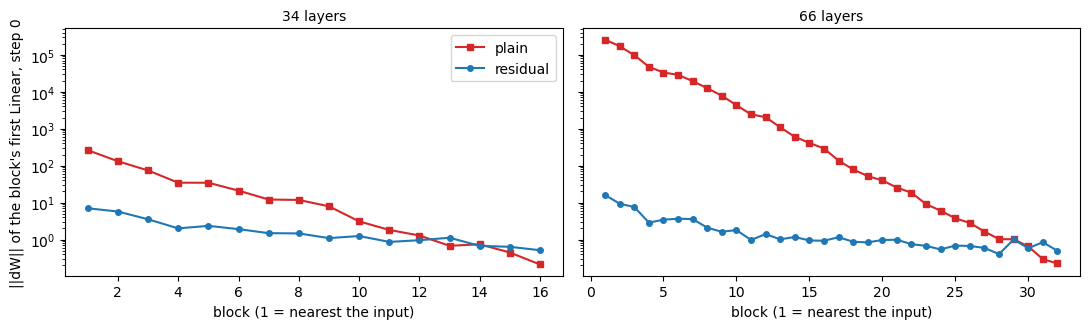

34 layers plain   : first block / last block = 1,238.9
34 layers residual: first block / last block = 13.7
66 layers plain   : first block / last block = 1,146,622.2
66 layers residual: first block / last block = 32.3


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
ratio = {}
for ax, D in zip(axes, (16, 32)):
    for residual, c, lab in ((False, 'tab:red', 'plain'), (True, 'tab:blue', 'residual')):
        g = np.array(canon.train_toy_vectorized(D, residual, seed=0, steps=1)['grad_norms'])
        ratio[(D, residual)] = g[0] / g[-1]
        ax.semilogy(np.arange(1, D + 1), g, 'o-' if residual else 's-', c=c, ms=4, label=lab)
    ax.set_title(f'{2 * D + 2} layers', fontsize=10); ax.set_xlabel('block (1 = nearest the input)')
axes[0].set_ylabel('||dW|| of the block\'s first Linear, step 0'); axes[0].legend()
plt.tight_layout(); plt.show()
for (D, residual), r in sorted(ratio.items()):
    print(f"{2 * D + 2} layers {'residual' if residual else 'plain   '}: first block / last block = {r:,.1f}")
assert ratio[(16, False)] > 50 * ratio[(16, True)]

The gradients do not vanish. In the plain networks they **explode** toward the input: the
first block of the 34-layer net is pushed more than a thousand times harder than the last, and
at 66 layers the factor is over a million. (It is BatchNorm itself that does this in
deep networks without shortcuts — Yang et al. proved it in 2019, four years after ResNet.)
No single learning rate suits layers whose gradients differ by five orders of magnitude: small
enough for the input side, it is far too small for the output side. In the residual twins
the profile is nearly flat at every depth.

A second symptom: the deep plain network's training is **chaotic**. Change one stem weight by
one part in $10^{12}$ and train both copies:

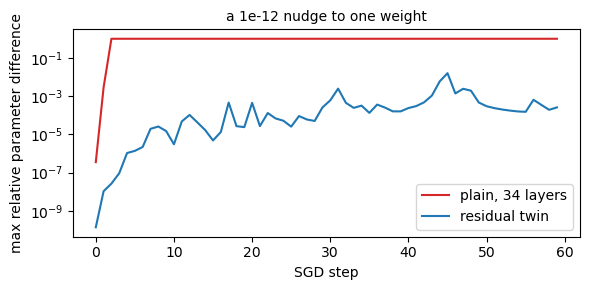

after 60 steps: plain 1.0e+00, residual 2.6e-04


In [5]:
def drift(residual, steps=60, D=16, eps=1e-12):
    # Two copies of the same toy net, one with a single weight nudged by eps
    # (relative); the largest relative parameter difference, step by step.
    nets = [canon.build_toy_net(D, residual) for _ in range(2)]
    nets[1].layers[0].W[0, 0] *= 1 + eps
    opts = [ng.SGD(lr=canon.TOY_LR, momentum=canon.TOY_MOM) for _ in range(2)]
    ll = ng.SoftmaxCrossEntropy(); out = []
    for _ in range(steps):
        for net, opt in zip(nets, opts):
            net.train(); ll.forward(net.forward(X), y); net.backward(ll.backward()); opt.step(net.params(), net.grads())
        out.append(max(rel_error(a, b) for a, b in zip(nets[0].params(), nets[1].params())))
    return np.array(out)

d_plain, d_res = drift(False), drift(True)
fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogy(d_plain, c='tab:red', label='plain, 34 layers'); ax.semilogy(d_res, c='tab:blue', label='residual twin')
ax.set_xlabel('SGD step'); ax.set_ylabel('max relative parameter difference'); ax.legend()
ax.set_title('a 1e-12 nudge to one weight', fontsize=10); plt.tight_layout(); plt.show()
print(f'after 60 steps: plain {d_plain[-1]:.1e}, residual {d_res[-1]:.1e}')
assert d_plain[-1] > 1e3 * d_res[-1]

In the plain network a rounding-sized difference grows by orders of magnitude per step until
the two copies are different networks (the relative difference saturates at 1). The residual
twin amplifies it too — training at a high learning rate always does a little — but sixty
steps later its two copies still agree to a few parts in ten thousand. This is not an
academic curiosity: it is why `tests/test_agreement.py` can compare the vectorized
library with the C-order mirror after three training steps for the residual twin, but only at
step zero for the plain one — two *correct* implementations, summing in different orders,
drift apart within a few steps. (C and the C-order mirror sum in the same order, so they still
agree to the last digit after all 400.)

Balduzzi et al. (2017) found a third symptom, and named it: **shattered gradients**. Walk the
input along a line and watch how the network's output responds — the derivative of one logit
with respect to the input, point by point (BatchNorm frozen at the line's own statistics, so
each point's derivative is its own):

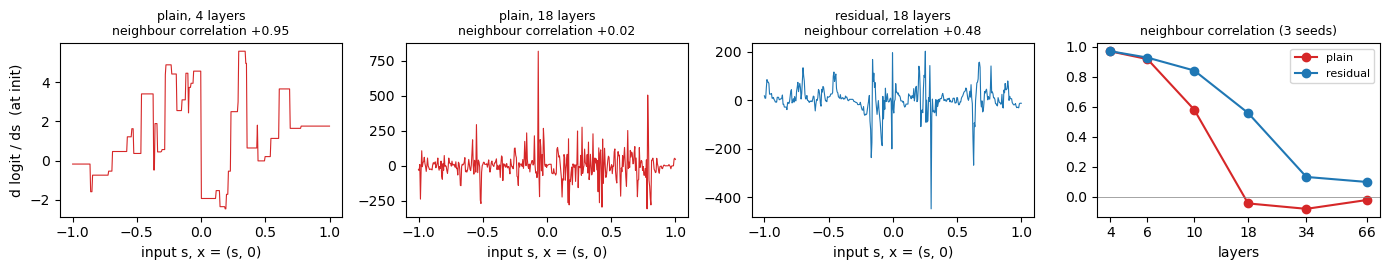

layers:               [4, 6, 10, 18, 34, 66]
plain     correlation: [ 0.97  0.92  0.58 -0.05 -0.08 -0.02]
residual  correlation: [0.97 0.93 0.84 0.56 0.13 0.1 ]


In [6]:
def neighbour_corr(D, residual, seeds=range(3)):
    # Correlation between the input-gradients of neighbouring points, averaged over seeds.
    return float(np.mean([np.corrcoef(g[:-1], g[1:])[0, 1]
                          for g in (canon.input_gradients(D, residual, seed=s)[1] for s in seeds)]))

fig, axes = plt.subplots(1, 4, figsize=(14, 2.8))
for ax, (D, residual, lab) in zip(axes[:3], ((1, False, 'plain, 4 layers'), (8, False, 'plain, 18 layers'),
                                             (8, True, 'residual, 18 layers'))):
    s, g = canon.input_gradients(D, residual)
    ax.plot(s, g, lw=0.8, c='tab:blue' if residual else 'tab:red')
    ax.set_title(f'{lab}\nneighbour correlation {np.corrcoef(g[:-1], g[1:])[0, 1]:+.2f}', fontsize=9)
    ax.set_xlabel('input s, x = (s, 0)')
axes[0].set_ylabel('d logit / ds  (at init)')
corr = {res: [neighbour_corr(D, res) for D in DEPTHS] for res in (False, True)}
for res, c in ((False, 'tab:red'), (True, 'tab:blue')):
    axes[3].plot(L, corr[res], 'o-', c=c, label='residual' if res else 'plain')
axes[3].axhline(0, c='gray', lw=0.5); axes[3].set_xscale('log', base=2); axes[3].set_xticks(L, L)
axes[3].set_xlabel('layers'); axes[3].set_title('neighbour correlation (3 seeds)', fontsize=9); axes[3].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('layers:              ', L)
for res in (False, True):
    print(f"{'residual' if res else 'plain':9s} correlation:", np.round(corr[res], 2))
assert all(r > p for r, p in zip(corr[True][1:], corr[False][1:]))

The shallow network's input-gradient is a smooth curve. By 18 layers the plain network's is
noise — neighbouring inputs, a hair apart, get uncorrelated gradients, so a step that helps one
point is a random kick to its neighbours — while its residual twin's still has visible
structure. Across depth, the plain networks' correlation collapses to zero by 18 layers; the
residual networks' decays too, but slowly. That is Balduzzi et al.'s result, measured:
correlations falling off exponentially with depth in plain networks and far more gently with
skip connections. (Note what it does *not* say: the plain 18-layer network still trains, and
the 66-layer residual one fits the spirals with a correlation near 0.1. Shattering is one
symptom, not the whole disease.) Exploding, chaotic, shattered: three views of a loss that
becomes, with depth, too wrinkled for gradient descent to follow. How does one `+` iron it
out?

## 4. The residual block

A plain block asks its layers to produce the block's output, $y = \mathrm{relu}(\mathcal{F}(x))$.
A residual block asks them for the *change* to its input:

$$y = \mathrm{relu}\big(\mathcal{F}(x) + x\big).$$

**The forward view.** If the best thing a block can do is nothing — pass its input on — a
plain block must build the identity out of weights, BatchNorms and ReLUs, which is hard; a
residual block just drives $\mathcal{F}$ to zero, which is where small random weights already
almost are. Doing nothing is the default, so extra blocks cost nothing — the paper's
hypothesis, and exactly the deeper-contains-shallower argument made easy for the optimizer.

**The backward view.** $x$ reaches the sum by two routes, so its gradient is the sum of the
two (the chain rule's rule for a value used twice). With $z = \mathcal{F}(x) + x$:

$$\frac{\partial L}{\partial x} = \frac{\partial L}{\partial z}\,\frac{\partial \mathcal{F}}{\partial x} \;+\; \frac{\partial L}{\partial z}.$$

The second term never passes through a layer. Stack blocks and drop the ReLU after the add
(He et al.'s 2016 "pre-activation" form): then $x_L = x_\ell + \sum_{i=\ell}^{L-1} \mathcal{F}(x_i)$
and

$$\frac{\partial L}{\partial x_\ell} = \frac{\partial L}{\partial x_L}\Big(1 + \frac{\partial}{\partial x_\ell}\sum_{i=\ell}^{L-1}\mathcal{F}(x_i)\Big):$$

whatever happens inside the blocks, a copy of the output's gradient arrives at *every* block
unmultiplied — the "1". In code the forward pass gains one `+` and the backward pass one `+`,
where the two routes meet again (`nanograd.Residual.backward`).

In [7]:
rng = np.random.default_rng(0)
body = [ng.Linear(6, 6, bias=False), ng.BatchNorm(6), ng.ReLU(), ng.Linear(6, 6, bias=False), ng.BatchNorm(6)]
blk = ng.Residual(body)
for p in blk.params():
    p[...] = rng.standard_normal(p.shape)
Xb = rng.standard_normal((10, 6)); Yb = blk.forward(Xb); dYb = rng.standard_normal(Yb.shape)
dXb = blk.backward(dYb)
err = rel_error(dXb, eval_numerical_gradient_array(lambda _: blk.forward(Xb), Xb, dYb))
print(f'Residual dX vs finite differences: rel_error = {err:.1e}'); assert err < 1e-6

# The two routes back, separately: through the body, and straight down the shortcut,
# where dL/dz arrives at x untouched -- dX is exactly their sum.
dZ = blk.act.backward(dYb)
print('dX == (gradient through the body) + dL/dz:', np.array_equal(dXb, blk.body.backward(dZ) + dZ))

# "Doing nothing is the default": zero the last BatchNorm's scale and shift and the
# block passes non-negative inputs through untouched -- the identity, for free.
body[4].gamma[:] = 0.0; body[4].beta[:] = 0.0
Xpos = np.abs(Xb)
print('block with gamma = beta = 0 is the identity:', np.allclose(blk.forward(Xpos), Xpos))

Residual dX vs finite differences: rel_error = 7.9e-10
dX == (gradient through the body) + dL/dz: False
block with gamma = beta = 0 is the identity: True


That last line is a trick in its own right: initialize every block's final BatchNorm scale
to zero and a ResNet of any depth *starts* as the shallow network made of its stem and head,
then grows into its depth as training moves the scales (Goyal et al., 2017, use it to train
ImageNet ResNets in an hour). The plain twin has no such option: zero its scale and the block
outputs zeros.

## 5. Batch normalization

Ioffe & Szegedy (February 2015) noticed that every layer of a deep network is chasing a moving
target: as the layers below it learn, the distribution of its inputs shifts, and it must keep
re-adapting. Their fix normalizes each channel to mean 0 and variance 1 *using the current
mini-batch's own statistics*, then lets the network rescale:

$$\mu_c = \frac{1}{m}\sum_i x_i, \quad \sigma_c^2 = \frac{1}{m}\sum_i (x_i - \mu_c)^2, \quad
\hat{x}_i = \frac{x_i - \mu_c}{\sqrt{\sigma_c^2 + \epsilon}}, \quad y_i = \gamma_c\,\hat{x}_i + \beta_c,$$

over the $m$ values channel $c$ takes in the batch (for a conv layer, every pixel of every
image). The learned $\gamma, \beta$ can undo the normalization entirely, so nothing is lost —
and $\beta$ does a bias's job, which is why the layer before a BatchNorm goes without one.
With it, an Inception network reached its old accuracy in **14× fewer steps** and tolerated
learning rates 30× higher; the ResNet paper puts a BatchNorm after every convolution.

**Backward.** Every $x_j$ moves every $\hat{x}_i$ — directly, and through $\mu$ and
$\sigma^2$, which the whole batch shares — so with $g_i = \partial L / \partial y_i$:

$$\frac{\partial \hat{x}_i}{\partial x_j} = \frac{1}{\sqrt{\sigma^2+\epsilon}}\Big([i=j] - \frac{1}{m} - \frac{\hat{x}_i \hat{x}_j}{m}\Big)
\;\;\Longrightarrow\;\;
\frac{\partial L}{\partial x_j} = \frac{\gamma}{m\sqrt{\sigma^2+\epsilon}}\Big(m\,g_j - \underbrace{\textstyle\sum_i g_i}_{\partial L/\partial \beta} - \hat{x}_j \underbrace{\textstyle\sum_i g_i \hat{x}_i}_{\partial L/\partial \gamma}\Big).$$

The two subtracted terms remove the components of the gradient along the two directions the
forward pass made irrelevant — shifting all of a channel's values by a constant (the mean
absorbs it) and scaling them all (the variance absorbs it). So the input gradient of every
channel sums to exactly zero, and is orthogonal to $\hat{x}$ up to the small $\epsilon$ —
which keeps a rescaling from being absorbed *completely*: $\sum_j \hat{x}_j\,\partial L/\partial x_j
= \gamma\,\frac{\partial L}{\partial \gamma}\,\frac{\epsilon}{\sqrt{\sigma^2+\epsilon}\,(\sigma^2+\epsilon)}$.

**Training vs evaluation.** A batch's statistics are an estimate, and at test time there may
be no batch. During training BatchNorm keeps running averages of $\mu$ and of the unbiased
$\sigma^2$; `net.eval()` swaps them in, turning every BatchNorm into a fixed per-channel
affine map.

In [8]:
rng = np.random.default_rng(1)
bn = ng.BatchNorm(4)
bn.gamma[:] = [1.0, 2.0, 0.5, 1.5]; bn.beta[:] = [0.0, -1.0, 3.0, 0.5]
Xn = rng.standard_normal((8, 4, 5, 5)) * [[[[3.0]], [[0.2]], [[1.0]], [[5.0]]]] + [[[[10.0]], [[-2.0]], [[0.0]], [[4.0]]]]
Yn = bn.forward(Xn)
print('channel means before:', Xn.mean(axis=(0, 2, 3)), '\n             after: ', Yn.mean(axis=(0, 2, 3)), '(= beta)')
print('channel stds  before:', Xn.std(axis=(0, 2, 3)), '\n             after: ', Yn.std(axis=(0, 2, 3)), '(= |gamma|)')
print(f'forward vs Algorithm 1 (the definition): max|diff| = '
      f'{np.abs(Yn - canon.naive_batchnorm_forward(Xn, bn.gamma, bn.beta)).max():.1e}')

dYn = rng.standard_normal(Yn.shape); dXn = bn.backward(dYn)
print(f'backward vs the full m x m Jacobian:  max|diff| = '
      f'{np.abs(dXn - canon.naive_batchnorm_backward(Xn, bn.gamma, dYn)).max():.1e}')
for name, analytic, wrt in (('dX', dXn, Xn), ('dgamma', bn.dgamma, bn.gamma), ('dbeta', bn.dbeta, bn.beta)):
    err = rel_error(analytic, eval_numerical_gradient_array(lambda _: bn.forward(Xn), wrt, dYn))
    print(f'  {name:6s} vs finite differences: rel_error = {err:.1e}'); assert err < 1e-6
s0, s1 = dXn.sum(axis=(0, 2, 3)), (dXn * bn.xhat).sum(axis=(0, 2, 3))
pred = bn.gamma * bn.dgamma * bn.eps * bn.invstd ** 3            # the epsilon term above
print('per channel, sum(dX) =', s0, '\n             sum(dX * xhat) =', s1, ' predicted by the eps term:', pred)
assert np.abs(s0).max() < 1e-10 and np.allclose(s1, pred, rtol=1e-6, atol=1e-14)

# Running statistics: after many batches from the same source they approach the
# population's; evaluation then uses them (and ignores the batch in front of it).
bn2 = ng.BatchNorm(1)
for _ in range(200):
    bn2.forward(rng.standard_normal((256, 1)) * 3.0 + 7.0)
print(f'running mean {bn2.running_mean[0]:.2f} (true 7), running var {bn2.running_var[0]:.2f} (true 9)')
bn2.training = False; one = np.array([[7.0]])          # what net.eval() does to every BatchNorm
print('evaluation mode normalizes even a batch of ONE value:', bn2.forward(one).ravel())

channel means before: [ 9.9325 -2.0142 -0.0658  3.4309] 
             after:  [ 0.  -1.   3.   0.5] (= beta)
channel stds  before: [3.0855 0.1867 0.9481 5.085 ] 
             after:  [1.     1.9997 0.5    1.5   ] (= |gamma|)
forward vs Algorithm 1 (the definition): max|diff| = 5.3e-15
backward vs the full m x m Jacobian:  max|diff| = 1.1e-14


  dX     vs finite differences: rel_error = 7.1e-08
  dgamma vs finite differences: rel_error = 1.0e-11
  dbeta  vs finite differences: rel_error = 6.9e-12
per channel, sum(dX) = [ 0.  0.  0. -0.] 
             sum(dX * xhat) = [-0.      0.0518 -0.0001 -0.    ]  predicted by the eps term: [-0.      0.0518 -0.0001 -0.    ]
running mean 6.96 (true 7), running var 9.12 (true 9)
evaluation mode normalizes even a batch of ONE value: [0.0141]


BatchNorm has a second job inside a ResNet: keeping the residual sums in scale. Each block
*adds* a branch to its input, so the signal's variance grows with depth unless something
bounds the branches. Measure the activations' spread at initialization, block by block, for
the four combinations:

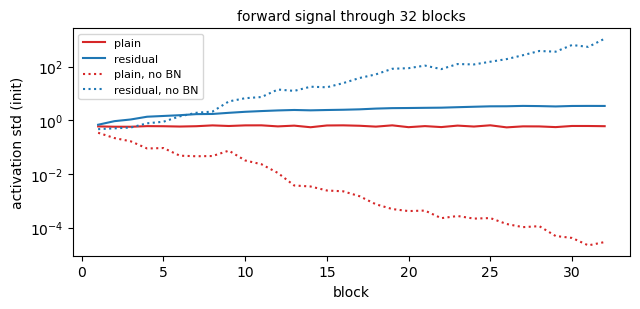

residual with BN: std grows 5.0x over 32 blocks;  without BN: 2.4e+03x


In [9]:
def act_std(D, residual, bn, width=canon.WIDTH, seed=0):
    # Std of each block's output at initialization (forward only), on the spirals.
    r = Rng(canon.TOY_SEED + seed); stem = ng.Linear(2, width); ng.he_normal(stem.W, r)
    a = np.maximum(stem.forward(X), 0); out = []
    for _ in range(D):
        l1, l2 = ng.Linear(width, width, bias=False), ng.Linear(width, width, bias=False)
        ng.he_normal(l1.W, r); ng.he_normal(l2.W, r)
        z = l1.forward(a); z = ng.BatchNorm(width).forward(z) if bn else z
        z = l2.forward(np.maximum(z, 0)); z = ng.BatchNorm(width).forward(z) if bn else z
        a = np.maximum(z + a if residual else z, 0); out.append(a.std())
    return out

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for residual, bn, c, ls in ((False, True, 'tab:red', '-'), (True, True, 'tab:blue', '-'),
                            (False, False, 'tab:red', ':'), (True, False, 'tab:blue', ':')):
    s = act_std(32, residual, bn)
    ax.semilogy(np.arange(1, 33), s, ls, c=c, label=f"{'residual' if residual else 'plain'}{'' if bn else ', no BN'}")
ax.set_xlabel('block'); ax.set_ylabel('activation std (init)'); ax.legend(fontsize=8)
ax.set_title('forward signal through 32 blocks', fontsize=10); plt.tight_layout(); plt.show()
s_res, s_nobn = act_std(32, True, True), act_std(32, True, False)
print(f'residual with BN: std grows {s_res[-1] / s_res[0]:.1f}x over 32 blocks;  without BN: {s_nobn[-1] / s_nobn[0]:.1e}x')

Without BatchNorm a residual stack doubles its variance at every block — the branch is as
large as its input and they add — so 32 blocks multiply the signal's scale by thousands.
With a BatchNorm closing every branch, each block adds a unit-variance term and
the spread grows only like the square root of the depth. The plain networks hold their scale
either way (He initialization was designed for exactly that), which is another way of seeing
that the plain net's failure was never about the *forward* signal.

## 6. The fix: residual twins of every depth

Same sweep, same seeds, same initial weights — each block now adds its input back.

(170s)
 layers  plain acc  residual acc  plain loss  residual loss
      4      1.000         1.000      0.0007       6.20e-04
      6      1.000         1.000      0.0003       2.64e-04
     10      1.000         1.000      0.0003       1.08e-04
     18      1.000         1.000      0.0004       4.41e-05
     34      0.644         1.000      0.4656       1.96e-05
     66      0.522         1.000      0.4856       1.46e-05


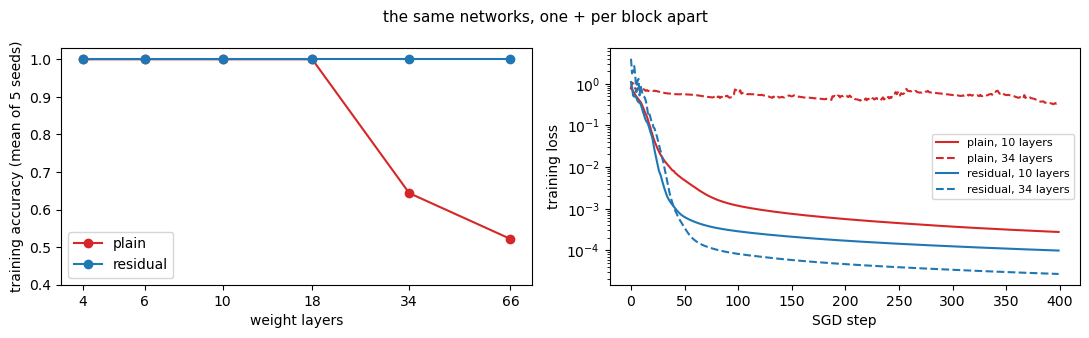

In [10]:
t0 = time.time()
for D in DEPTHS:
    sweep[True][D] = [canon.train_toy_vectorized(D, residual=True, seed=s) for s in SEEDS]
print(f'({time.time() - t0:.0f}s)')
print(f"{'layers':>7s} {'plain acc':>10s} {'residual acc':>13s} {'plain loss':>11s} {'residual loss':>14s}")
for D in DEPTHS:
    p, r = sweep[False][D], sweep[True][D]
    print(f"{2 * D + 2:7d} {np.mean([x['acc'] for x in p]):10.3f} {np.mean([x['acc'] for x in r]):13.3f} "
          f"{np.mean([x['loss'][-1] for x in p]):11.4f} {np.mean([x['loss'][-1] for x in r]):14.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for residual, c, lab in ((False, 'tab:red', 'plain'), (True, 'tab:blue', 'residual')):
    axes[0].plot(L, [np.mean([r['acc'] for r in sweep[residual][D]]) for D in DEPTHS], 'o-', c=c, label=lab)
axes[0].set_xscale('log', base=2); axes[0].set_xticks(L, L); axes[0].set_ylim(0.4, 1.03)
axes[0].set_xlabel('weight layers'); axes[0].set_ylabel('training accuracy (mean of 5 seeds)'); axes[0].legend()
for residual, c in ((False, 'tab:red'), (True, 'tab:blue')):
    for D, ls in ((4, '-'), (16, '--')):
        axes[1].plot(sweep[residual][D][0]['loss'], ls, c=c, label=f"{'residual' if residual else 'plain'}, {2 * D + 2} layers")
axes[1].set_yscale('log'); axes[1].set_xlabel('SGD step'); axes[1].set_ylabel('training loss'); axes[1].legend(fontsize=8)
fig.suptitle('the same networks, one + per block apart', fontsize=11)
plt.tight_layout(); plt.show()
assert all(np.mean([r['acc'] for r in sweep[True][D]]) == 1.0 for D in DEPTHS)

Every residual network fits every point at every depth, and its loss falls *faster* the deeper
it is — the right panel's two blue curves cross the red ones in opposite order. This is the
paper's whole argument in one table: the plain and residual networks have identical
parameters, identical arithmetic and identical initial weights; the only difference is a `+`
in each block's forward pass and the matching `+` in its backward pass.

## 7. Verify against the canonical `resnet.py` and the C mirror

`ToyResNet` runs both twins with every sum in `lib/c/nanograd`'s loop order, from the same LCG
streams as `c/resnet.c`. `tests/test_agreement.py` compiles the C and asserts both twins'
fingerprints match — even the chaotic plain one, because nothing differs between the two
computations, not even the order of a single addition.

In [11]:
t0 = time.time()
fp = {res: dict(canon.run_toy(residual=res)) for res in (False, True)}
print(f"{'':11s}{'plain':>24s}{'residual':>24s}   ({time.time() - t0:.0f}s of C-order NumPy)")
for k in fp[True]:
    print(f'{k:11s}{fp[False][k]:24.15g}{fp[True][k]:24.15g}')
assert fp[True]['acc'] == 1.0 and fp[False]['acc'] < fp[True]['acc'] - 0.2
print('OK: the 34-layer plain net degrades, its residual twin fits every point; c/resnet.c prints '
      'the same digits (see tests/test_agreement.py)')

                              plain                residual   (79s of C-order NumPy)
loss               1.12682554378094    3.37199916117306e-05
acc                         0.59375                       1
batch_loss        0.455325451059899    2.70640623938868e-05
wsum               542.036584624673        485.777218238362
w0_00                14.69876016086      -0.732048815331604
w1_00              1.16595609695326       -0.05425118355712
g2_last           0.775593453241689       0.898023495274716
rv2_last           1.64762383684502        2.65641363383025
OK: the 34-layer plain net degrades, its residual twin fits every point; c/resnet.c prints the same digits (see tests/test_agreement.py)


## 8. CIFAR-10: the paper's networks

Section 4.2 of the paper describes a family of CIFAR-10 networks small enough to study
depth on — and they are small enough for NumPy:

    32x32x3 -> conv 3x3, 16 -> BN -> ReLU
            -> n basic blocks at 16 channels                   32x32
            -> n basic blocks at 32 channels (first at stride 2) 16x16
            -> n basic blocks at 64 channels (first at stride 2)  8x8
            -> global average pooling -> Linear(64 -> 10)
    basic block: conv 3x3 -> BN -> ReLU -> conv 3x3 -> BN (+ shortcut) -> ReLU

That is $6n + 2$ weight layers: $n = 3$ gives ResNet-20, $n = 9$ ResNet-56. Where a block
halves the resolution and doubles the width, its input no longer matches its output, so the
shortcut takes every second pixel and pads the new channels with zeros — the paper's
**option (A)**, parameter-free, so a ResNet has *exactly* its plain twin's parameters. There
is no dense layer to speak of: global average pooling turns each final 8×8 map into one
number, and one `Linear` classifies — none of the dense layers that held 96% of AlexNet's
weights.

The training recipe is the paper's: He initialization, BatchNorm after every convolution, no
dropout, **SGD with momentum 0.9 at learning rate 0.1**, divided by 10 twice; batch 128;
4-pixel padding, random 32×32 crops and mirroring. Module 04 had to replace AlexNet's SGD
with Adam because a plain 8-layer network without batch normalization learned too slowly
under it — with BatchNorm, the old optimizer at a high learning rate is simply the best
choice. Two economies keep it on a laptop: eight epochs instead of the paper's 182 (so
weight decay $5\times10^{-4}$ instead of $10^{-4}$, the usual pairing for short schedules),
and, for the depth experiment, half the paper's widths on photos shrunk to 16×16 — each
pixel the average of a 2×2 block — which cuts a training step's cost by about eight while
keeping all 50,000 images and every one of the 3,128 SGD steps.

Every run is cached under `data/cifar10/checkpoints/` (gitignored), keyed by a hash of its
full configuration; loaded networks are re-evaluated from their weights. Delete the folder to
retrain (many hours of NumPy on a laptop CPU).

In [12]:
from get_cifar10 import CLASSES
data = canon.load_cifar()
Xtr_c, ytr_c, Xte_c, yte_c, mean, std = data
print('train', Xtr_c.shape, Xtr_c.dtype, ' test', Xte_c.shape)
probe = canon.build_resnet(n=3)
print(f'ResNet-20: {canon.n_layers(probe)} weight layers, {canon.n_params(probe):,} parameters '
      f'(the paper: 0.27M); AlexNet-mini (Module 04): 348,874')
a = canon.standardize(Xtr_c[:2], mean, std)
for i, layer in enumerate(probe.layers):
    a = layer.forward(a)
    if i in (0, 3, 6, 9, 12) or i == len(probe.layers) - 1:
        print(f'  after layer {i:2d} {type(layer).__name__:16s} -> {a.shape}')

train (50000, 3, 32, 32) uint8  test (10000, 3, 32, 32)


ResNet-20: 20 weight layers, 269,722 parameters (the paper: 0.27M); AlexNet-mini (Module 04): 348,874
  after layer  0 Conv2D           -> (2, 16, 32, 32)
  after layer  3 Residual         -> (2, 16, 32, 32)
  after layer  6 Residual         -> (2, 32, 16, 16)
  after layer  9 Residual         -> (2, 64, 8, 8)
  after layer 12 GlobalAvgPool2D  -> (2, 64)
  after layer 13 Linear           -> (2, 10)


### 8.1 Gradients at initialization, on real photos

The toy's measurement, on a batch of 128 CIFAR images: the gradient norm of every
convolution's kernel on the first step, for the depth experiment's 56-layer plain network and
its residual twin (half width, 16×16 photos).

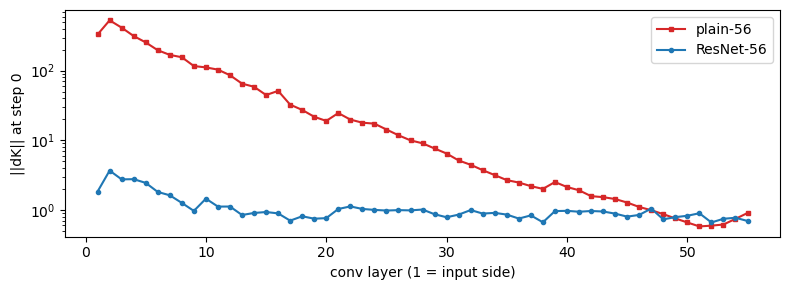

plain-56 : first block conv / last conv = 590.1, max/min over layers = 920.1
ResNet-56: first block conv / last conv = 5.3, max/min over layers = 5.6


In [13]:
w6 = canon.FIG6['widths']
X16 = canon.downsample(Xtr_c[:128])
gn = {res: canon.cifar_grad_norms(canon.build_resnet(n=9, residual=res, widths=w6),
                                  X16, ytr_c[:128], mean, std) for res in (False, True)}
fig, ax = plt.subplots(figsize=(8, 3))
for res, c in ((False, 'tab:red'), (True, 'tab:blue')):
    ax.semilogy(np.arange(1, len(gn[res]) + 1), gn[res], 'o-' if res else 's-', c=c, ms=3,
                label='ResNet-56' if res else 'plain-56')
ax.set_xlabel('conv layer (1 = input side)'); ax.set_ylabel('||dK|| at step 0'); ax.legend()
plt.tight_layout(); plt.show()
for res in (False, True):
    g = np.array(gn[res]); print(f"{'ResNet-56' if res else 'plain-56 '}: first block conv / last conv = {g[1] / g[-1]:.1f}, "
                                  f"max/min over layers = {g.max() / g.min():.1f}")

The toy's finding survives contact with real photos. At initialization the 56-layer plain network's first block receives about **600 times** the gradient of its last convolution, and the spread across all its layers is nearly a thousandfold; its residual twin's first and last differ by about 5. (Convolutional layers normalize over every pixel, so the explosion is milder than in the toy's dense layers — but a factor of 600 between the ends of one network is still far more than one learning rate can serve.)

### 8.2 The degradation problem on CIFAR-10 — Figure 6, redone

Four networks: plain and residual, 20 and 56 layers — half the paper's widths, 16×16 photos,
all 50,000 of them, eight epochs (3,128 SGD steps) of the full recipe, each warming up at
learning rate 0.01 for its first 400 steps as the paper did for its deepest network. The
paper's Figure 6 plots training error (thin) and test error (thick) against SGD steps, plain
nets on the left and ResNets on the right; so do we, with the training error of every 40
consecutive (augmented) batches as the thin curves.

[cifar] loaded checkpoint 4cec0da4ab03 (8 epochs, test_acc=0.6179)


[cifar] loaded checkpoint 9b6af3b1312a (8 epochs, test_acc=0.3454)


[cifar] loaded checkpoint de33f5504d6f (8 epochs, test_acc=0.6839)


[cifar] loaded checkpoint e6490b7c671a (8 epochs, test_acc=0.6864)


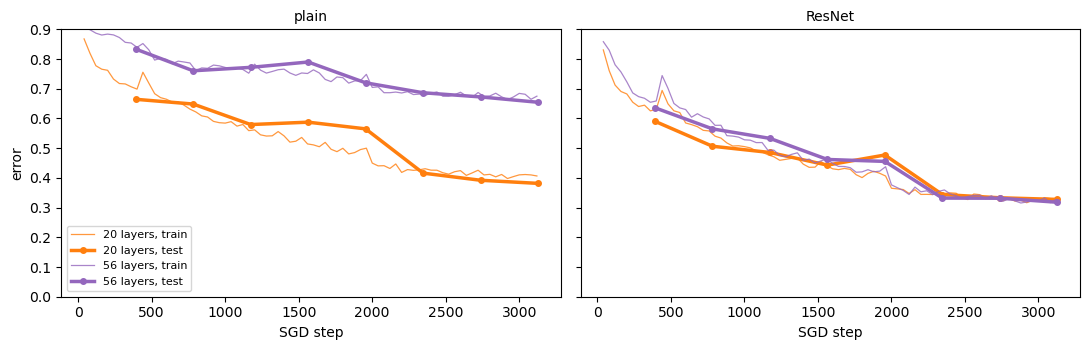

             final train err  test acc (all 10k)
plain-20               0.408              0.6179
plain-56               0.675              0.3454
ResNet-20              0.325              0.6839
ResNet-56              0.323              0.6864


In [14]:
fig6 = {}
for res in (False, True):
    for n in canon.FIG6_DEPTHS:
        _, acc, hist = canon.run_cifar(n=n, residual=res, data=data, cache=True, verbose=True, **canon.FIG6)
        fig6[(res, n)] = (acc, hist)

def trace(hist):
    pts = np.array([p for h in hist for p in h['trace']])
    return pts[:, 0], pts[:, 1]

steps_per_epoch = len(range(0, Xtr_c.shape[0], 128))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, res in zip(axes, (False, True)):
    for n, c in zip(canon.FIG6_DEPTHS, ('tab:orange', 'tab:purple')):
        acc, hist = fig6[(res, n)]
        st, err = trace(hist)
        ax.plot(st, err, '-', c=c, lw=0.9, alpha=0.8, label=f'{6 * n + 2} layers, train')
        ax.plot(steps_per_epoch * np.arange(1, len(hist) + 1), [1 - h['test_acc'] for h in hist],
                'o-', c=c, lw=2.5, ms=4, label=f'{6 * n + 2} layers, test')
    ax.set_title('plain' if not res else 'ResNet', fontsize=10); ax.set_xlabel('SGD step')
    ax.set_ylim(0, 0.9)
axes[0].set_ylabel('error'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{'':12s}{'final train err':>16s}{'test acc (all 10k)':>20s}")
for res in (False, True):
    for n in canon.FIG6_DEPTHS:
        acc, hist = fig6[(res, n)]
        print(f"{('ResNet' if res else 'plain') + '-' + str(6 * n + 2):12s}{hist[-1]['train_err']:16.3f}{acc:20.4f}")
p20, p56 = fig6[(False, 3)][1][-1]['train_err'], fig6[(False, 9)][1][-1]['train_err']
r20, r56 = fig6[(True, 3)][1][-1]['train_err'], fig6[(True, 9)][1][-1]['train_err']
assert p56 > p20 + 0.1 and r56 < r20 + 0.01 and r56 < p56 - 0.2    # deeper: much worse plain, no worse residual

The paper's Figure 6, on a laptop. **Plain networks (left):** after 3,128 steps the 56-layer network's training error is **67.5%** where the 20-layer one's is **40.8%** — the deeper network fits its own training data far worse, from the first epoch to the last, and its test accuracy (34.5%) is little more than half the shallow one's (61.8%). Same blocks, same data, same recipe, more of them. **ResNets (right):** the 56-layer network finishes level with the 20-layer one (32.3% against 32.5% training error, 68.6% against 68.4% test accuracy) — depth no longer hurts, and both beat the best plain network. On this short budget the deeper ResNet only ties; the paper's ResNet-56 beats its ResNet-20 by 1.8 points after 182 epochs, a margin eight epochs cannot resolve. The starkest number is across the panels: at 56 layers, the residual network reaches **68.6%** test accuracy and its plain twin, with exactly the same parameters, **34.5%**.

### 8.3 The paper's ResNet-20 (target ≥ 80%)

Full width (16/32/64), all 50,000 training images, the full recipe: the canonical
configuration of `run_cifar()`.

[cifar] loaded checkpoint 78324d2ce671 (8 epochs, test_acc=0.8399)
  epoch 0  lr=0.100  train_loss=1.6161  train_err=0.5955  test_acc=0.4748
  epoch 1  lr=0.100  train_loss=1.0846  train_err=0.3886  test_acc=0.6457
  epoch 2  lr=0.100  train_loss=0.8644  train_err=0.3018  test_acc=0.6328
  epoch 3  lr=0.100  train_loss=0.7618  train_err=0.2633  test_acc=0.6423
  epoch 4  lr=0.100  train_loss=0.7019  train_err=0.2441  test_acc=0.6745
  epoch 5  lr=0.010  train_loss=0.5259  train_err=0.1814  test_acc=0.8218
  epoch 6  lr=0.010  train_loss=0.4783  train_err=0.1645  test_acc=0.8284
  epoch 7  lr=0.001  train_loss=0.4483  train_err=0.1521  test_acc=0.8399



CIFAR-10 test accuracy = 0.8399   (target >= 0.80; AlexNet-mini, Module 04: 0.7233 with 348,874 parameters)


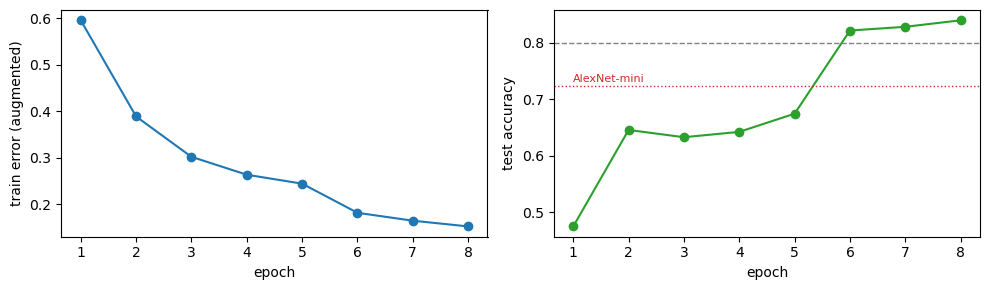

per-class accuracy: {'airplane': 0.867, 'automobile': 0.93, 'bird': 0.755, 'cat': 0.668, 'deer': 0.836, 'dog': 0.787, 'frog': 0.868, 'horse': 0.848, 'ship': 0.927, 'truck': 0.913}


In [15]:
net20, _, hist = canon.run_cifar(data=data, cache=True, verbose=True)
for h in hist:
    print(f"  epoch {h['epoch']}  lr={h['lr']:.3f}  train_loss={h['train_loss']:.4f}  train_err={h['train_err']:.4f}  test_acc={h['test_acc']:.4f}")
acc20 = canon.evaluate(net20, Xte_c, yte_c, mean, std)    # from the weights, not the record
print(f'\nCIFAR-10 test accuracy = {acc20:.4f}   (target >= 0.80; AlexNet-mini, Module 04: 0.7233 with 348,874 parameters)')
assert acc20 >= 0.80 and abs(acc20 - hist[-1]['test_acc']) < 1e-9
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
ep = np.arange(1, len(hist) + 1)
axes[0].plot(ep, [h['train_err'] for h in hist], 'o-'); axes[0].set_xlabel('epoch'); axes[0].set_ylabel('train error (augmented)')
axes[1].plot(ep, [h['test_acc'] for h in hist], 'o-', c='tab:green'); axes[1].axhline(0.80, ls='--', c='gray', lw=1)
axes[1].axhline(0.7233, ls=':', c='tab:red', lw=1); axes[1].text(1, 0.73, 'AlexNet-mini', color='tab:red', fontsize=8)
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('test accuracy')
plt.tight_layout(); plt.show()

net20.eval()
preds = np.concatenate([net20.forward(canon.standardize(Xte_c[s:s + 500], mean, std)).argmax(1) for s in range(0, 10000, 500)])
cm = np.zeros((10, 10), dtype=int); np.add.at(cm, (yte_c, preds), 1)
print('per-class accuracy:', {c: round(float(a), 3) for c, a in zip(CLASSES, cm.diagonal() / cm.sum(axis=1))})

**84.0%** after eight epochs — 11.7 points above Module 04's AlexNet-mini (72.3% after fifteen, with 348,874 parameters to ResNet-20's 269,722), with no dropout, no dense layers to speak of, and plain SGD at a learning rate of 0.1. While that rate held, test accuracy wandered between 63% and 68% from epoch to epoch; the first cut, at epoch 6, settled it at once into the low 80s. The paper's ResNet-20 reached 91.25% with the same network and 182 epochs: what separates the two numbers is the length of the schedule, not anything about the architecture.

### 8.4 Delete a block (Veit, Wilber & Belongie, 2016)

What has a ResNet actually learned? Veit et al. ran a lesion study: take a trained network
and, at test time, delete one block. In a plain network that is surgery on a chain — every
later layer was trained on what the deleted one produced. In a residual network a deleted
block leaves its shortcut, so the input passes on unchanged. We do it to the two 56-layer
networks from §8.2, scoring each lesioned network on 2,000 (16×16) test images.

plain-56 : intact 0.345;  one block deleted: mean 0.120, worst 0.041, best 0.235  (25 deletable blocks)


ResNet-56: intact 0.682;  one block deleted: mean 0.634, worst 0.423, best 0.679  (27 deletable blocks)


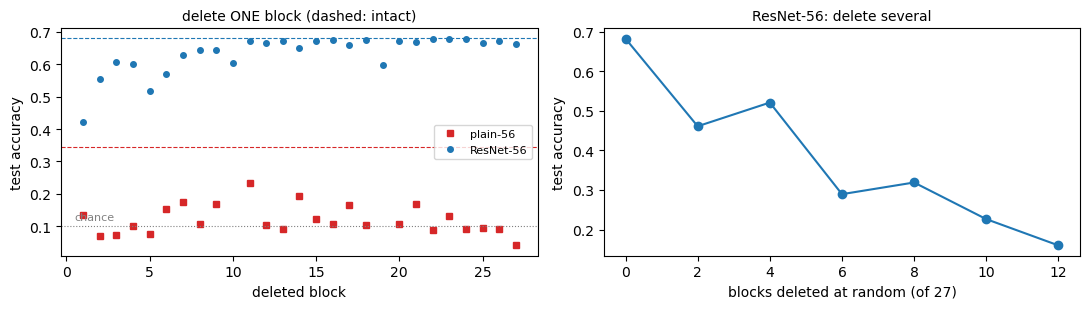

accuracy with k blocks deleted: {0: np.float64(0.682), 2: np.float64(0.461), 4: np.float64(0.521), 6: np.float64(0.289), 8: np.float64(0.319), 10: np.float64(0.226), 12: np.float64(0.16)}


In [16]:
Xl, yl = canon.downsample(Xte_c[:2000]), yte_c[:2000]
lesion = {}
for res in (False, True):
    net_l, _, _ = canon.run_cifar(n=9, residual=res, data=data, cache=True, **canon.FIG6)
    base = canon.evaluate(net_l, Xl, yl, mean, std)
    idx = canon.block_indices(net_l)
    accs = [canon.evaluate(canon.lesioned(net_l, i), Xl, yl, mean, std) if canon.deletable(net_l, i) else np.nan
            for i in idx]
    lesion[res] = (base, accs, net_l)
    ok = [a for a in accs if not np.isnan(a)]
    print(f"{'ResNet-56' if res else 'plain-56 '}: intact {base:.3f};  one block deleted: mean {np.mean(ok):.3f}, "
          f"worst {np.min(ok):.3f}, best {np.max(ok):.3f}  ({len(ok)} deletable blocks)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for res, c in ((False, 'tab:red'), (True, 'tab:blue')):
    base, accs, _ = lesion[res]
    axes[0].plot(np.arange(1, len(accs) + 1), accs, 'o' if res else 's', c=c, ms=4, label='ResNet-56' if res else 'plain-56')
    axes[0].axhline(base, c=c, lw=0.8, ls='--')
axes[0].axhline(0.1, c='gray', lw=0.8, ls=':'); axes[0].text(0.5, 0.12, 'chance', color='gray', fontsize=8)
axes[0].set_xlabel('deleted block'); axes[0].set_ylabel('test accuracy'); axes[0].legend(fontsize=8)
axes[0].set_title('delete ONE block (dashed: intact)', fontsize=10)

# Delete k random blocks at once (ResNet only; skip the two downsampling blocks).
base, _, net_r = lesion[True]
cand = [i for i in canon.block_indices(net_r) if net_r.layers[i].shortcut is None]
rng = np.random.default_rng(0); ks = list(range(0, 13, 2)); curve = []
for k in ks:
    trials = []
    for _ in range(3):
        m = net_r
        for i in sorted(rng.choice(cand, size=k, replace=False)):
            m = canon.lesioned(m, i)
        trials.append(canon.evaluate(m, Xl, yl, mean, std))
    curve.append(np.mean(trials))
axes[1].plot(ks, curve, 'o-', c='tab:blue'); axes[1].set_xlabel('blocks deleted at random (of 27)')
axes[1].set_ylabel('test accuracy'); axes[1].set_title('ResNet-56: delete several', fontsize=10)
plt.tight_layout(); plt.show()
print('accuracy with k blocks deleted:', dict(zip(ks, np.round(curve, 3))))

Delete any single block of the trained plain network and it collapses to chance or below — from 34.5% intact to 12.0% on average (between 4.1% and 23.5%, depending on the block): every later block was trained on what the deleted one produced. Delete any single block of the ResNet and it barely notices: 68.2% intact, 63.4% on average with one block gone. Deleting a block deep in the network costs under a point; the costly ones are the very first block (42.3%) and the two that downsample (about 60%), whose shortcuts have to change the representation's shape — Veit et al. saw the same. Delete several at once and the damage compounds — two random blocks cost about twenty points, twelve of the 27 bring it down to 16% — less gracefully than in Veit's fully trained 110-layer network (ours had eight epochs at half width), and with large swings depending on whether the dice pick the first block. The contrast is still the point: in the plain network, removing any one block leaves nothing that works; in the residual one, most blocks are corrections the rest of the network can do without.

## 9. The historical corner: what the ImageNet ResNets were

The CIFAR networks are the paper's small laboratory. The networks that won ILSVRC 2015 — and
every COCO 2015 track it entered — were built from the same idea at ImageNet scale:

- **A VGG-style stem and four stages.** A 7×7 stride-2 convolution and max-pool take the
  224×224 image to 56×56; four stages at 64, 128, 256 and 512 base channels halve the
  resolution at their first block; global average pooling and one 1000-way `Linear` finish.
- **Bottleneck blocks** for 50 layers and up: 1×1 conv down to a quarter of the width, 3×3
  conv, 1×1 conv back up — three layers for roughly the cost of two 3×3 convs at full width,
  which is how 152 layers cost *less* arithmetic than VGG-19.
- **Projection shortcuts** (option B): where shapes change, a 1×1 stride-2 conv instead of
  zero-padding. The paper found it slightly better than (A) on ImageNet and projecting
  *every* shortcut (C) marginally better still — "but the small differences among A/B/C
  indicate that projection shortcuts are not essential."
- **Too deep, at last.** On CIFAR-10 a 110-layer ResNet reached 6.43% error; a 1,202-layer one
  trained without difficulty to under 0.1% training error — and tested *worse* (7.93%). Past
  some depth the problem is overfitting again, the ordinary kind.

In [17]:
# Parameters and multiply-adds of the ImageNet networks, computed from their layer specs
# (224x224 input; convs + the final Linear; BN and biases omitted, as in the paper's count).
def conv_cost(cin, cout, k, hw):           # hw = output height*width
    return cin * cout * k * k, cin * cout * k * k * hw

def resnet_imagenet(blocks, bottleneck):
    P = M = 0
    p, m = conv_cost(3, 64, 7, 112 * 112); P += p; M += m
    cin, hw = 64, 56
    for stage, (nb, w) in enumerate(zip(blocks, (64, 128, 256, 512))):
        for b in range(nb):
            if stage > 0 and b == 0:
                hw //= 2
            out = 4 * w if bottleneck else w
            if bottleneck:
                specs = [(cin, w, 1), (w, w, 3), (w, out, 1)]
            else:
                specs = [(cin, w, 3), (w, w, 3)]
            for ci, co, k in specs:
                p, m = conv_cost(ci, co, k, hw * hw); P += p; M += m
            if cin != out:                                   # projection shortcut (option B)
                p, m = conv_cost(cin, out, 1, hw * hw); P += p; M += m
            cin = out
    P += cin * 1000; M += cin * 1000
    return P, M

def vgg(cfg):
    P = M = 0; cin, hw = 3, 224
    for v in cfg:
        if v == 'M':
            hw //= 2; continue
        p, m = conv_cost(cin, v, 3, hw * hw); P += p; M += m; cin = v
    for a, b in ((512 * 7 * 7, 4096), (4096, 4096), (4096, 1000)):
        P += a * b; M += a * b
    return P, M

nets = {'VGG-16': vgg([64, 64, 'M', 128, 128, 'M', 256, 256, 256, 'M', 512, 512, 512, 'M', 512, 512, 512, 'M']),
        'VGG-19': vgg([64, 64, 'M', 128, 128, 'M', 256, 256, 256, 256, 'M', 512, 512, 512, 512, 'M', 512, 512, 512, 512, 'M']),
        'ResNet-18': resnet_imagenet((2, 2, 2, 2), False), 'ResNet-34': resnet_imagenet((3, 4, 6, 3), False),
        'ResNet-50': resnet_imagenet((3, 4, 6, 3), True), 'ResNet-101': resnet_imagenet((3, 4, 23, 3), True),
        'ResNet-152': resnet_imagenet((3, 8, 36, 3), True)}
print(f"{'network':11s}{'params':>13s}{'mult-adds':>16s}")
for k, (p, m) in nets.items():
    print(f'{k:11s}{p / 1e6:11.1f} M{m / 1e9:13.2f} G')
print("(the paper's Table 1: ResNet-18/34/50/101/152 at 1.8/3.6/3.8/7.6/11.3 GFLOPs; VGG-16/19 at 15.3/19.6)")

network           params       mult-adds
VGG-16           138.3 M        15.47 G
VGG-19           143.7 M        19.63 G
ResNet-18         11.7 M         1.81 G
ResNet-34         21.8 M         3.66 G
ResNet-50         25.5 M         3.86 G
ResNet-101        44.4 M         7.57 G
ResNet-152        60.0 M        11.28 G
(the paper's Table 1: ResNet-18/34/50/101/152 at 1.8/3.6/3.8/7.6/11.3 GFLOPs; VGG-16/19 at 15.3/19.6)


ResNet-152 is nearly eight times as deep as VGG-19 and needs about 40% less arithmetic, with a
third of the parameters — most of VGG's sit in its three dense layers, which ResNet replaced
with global average pooling and a single `Linear`.

**The road not taken: gates.** Seven months before ResNet, Srivastava, Greff and Schmidhuber's
*Highway Networks* trained plain-style networks with hundreds of layers by giving each layer a
learned gate $T(x)$: $y = T(x)\,H(x) + (1 - T(x))\,x$. When the gate closes, the layer passes its
input through — a shortcut, opened and shut by the data. The idea came from the LSTM (Module
07), whose "constant error carousel" (1997) is the same trick through *time*: a path along
which the gradient is multiplied by one. ResNet is the gate held permanently open — no extra
parameters, nothing to learn about when to skip — and that simplicity is much of why it, and
not the highway network, became the default. A year later He et al.'s *Identity Mappings in
Deep Residual Networks* showed why the open gate matters: anything on the shortcut — a scale,
a gate, a dropout — multiplies the "1" in the gradient and, compounded over a hundred blocks,
brings back the problem it was meant to solve. Their pre-activation blocks (BatchNorm and ReLU
moved *inside* the branch, nothing after the add) trained a 1,001-layer CIFAR network to 4.62%.

## 10. Export for the animation

The Manim scene draws the toy's sweeps and gradient profiles, the shattered gradients, the
CIFAR curves, and the lesion results from exactly these runs.

In [18]:
s_line, g_plain = canon.input_gradients(8, False)          # 18 layers
_, g_res = canon.input_gradients(8, True)
payload = {
    'toy': {'layers': L,
            'plain_acc': [round(float(np.mean([r['acc'] for r in sweep[False][D]])), 4) for D in DEPTHS],
            'res_acc': [round(float(np.mean([r['acc'] for r in sweep[True][D]])), 4) for D in DEPTHS],
            'plain_loss_34': [round(float(v), 6) for v in sweep[False][16][0]['loss']],
            'res_loss_34': [round(float(v), 8) for v in sweep[True][16][0]['loss']],
            'plain_loss_10': [round(float(v), 8) for v in sweep[False][4][0]['loss']]},
    'toy_grad_norms': {'plain': canon.train_toy_vectorized(16, False, steps=1)['grad_norms'],
                       'res': canon.train_toy_vectorized(16, True, steps=1)['grad_norms']},
    'shattered': {'layers': 18, 's': np.round(s_line, 4).tolist(), 'plain': np.round(g_plain, 5).tolist(),
                  'res': np.round(g_res, 5).tolist(),
                  'corr_layers': L, 'corr_plain': np.round(corr[False], 3).tolist(),
                  'corr_res': np.round(corr[True], 3).tolist()},
    'fig6': {f"{'res' if res else 'plain'}{6 * n + 2}": {
                 'train_err': [round(h['train_err'], 4) for h in fig6[(res, n)][1]],
                 'test_err': [round(1 - h['test_acc'], 4) for h in fig6[(res, n)][1]],
                 'trace_step': trace(fig6[(res, n)][1])[0].astype(int).tolist(),
                 'trace_err': np.round(trace(fig6[(res, n)][1])[1], 4).tolist()}
             for res in (False, True) for n in canon.FIG6_DEPTHS},
    'cifar_grad_norms': {'plain56': gn[False], 'res56': gn[True]},
    'lesion': {'res_base': lesion[True][0], 'plain_base': lesion[False][0],
               'res': [None if np.isnan(a) else round(a, 4) for a in lesion[True][1]],
               'plain': [None if np.isnan(a) else round(a, 4) for a in lesion[False][1]]},
    'canonical': {'test_acc': round(acc20, 4), 'params': canon.n_params(net20)},
}
canon.export_assets(payload)

[export] wrote C:\Users\shaia\development\deep-learning-from-scratch\topics\05-resnet\anim\resnet_assets.json


## 11. Framework mirrors: PyTorch, TensorFlow, Keras

The mechanisms were built from scratch above. This closing section shows the same ideas
idiomatically in each framework and **validates** ours against them — PyTorch strictly (same
ops, same numbers, gradient for gradient), TensorFlow and Keras at the result level.

### 11.1 PyTorch — our BatchNorm *is* `F.batch_norm`, our block is autograd's

In [19]:
import torch
import torch.nn.functional as F
rng = np.random.default_rng(10)

# (a) BatchNorm, training mode: output, all three gradients, and the running statistics
# (torch also keeps the UNBIASED variance and weights the newest batch by momentum = 0.1).
bn = ng.BatchNorm(3); bn.gamma[:] = rng.standard_normal(3); bn.beta[:] = rng.standard_normal(3)
Xb = rng.standard_normal((4, 3, 5, 5)) * 2 + 1; Y_ours = bn.forward(Xb)
dYb = rng.standard_normal(Y_ours.shape); dX_ours = bn.backward(dYb)
Xt = torch.tensor(Xb, requires_grad=True); gt = torch.tensor(np.ones(3) * bn.gamma, requires_grad=True)
bt = torch.tensor(np.ones(3) * bn.beta, requires_grad=True)
rm, rv = torch.zeros(3, dtype=torch.float64), torch.ones(3, dtype=torch.float64)
Yt = F.batch_norm(Xt, rm, rv, gt, bt, training=True, momentum=0.1, eps=1e-5); Yt.backward(torch.tensor(dYb))
for name, ours, t in [('Y', Y_ours, Yt.detach()), ('dX', dX_ours, Xt.grad), ('dgamma', bn.dgamma, gt.grad),
                      ('dbeta', bn.dbeta, bt.grad), ('running_mean', bn.running_mean, rm), ('running_var', bn.running_var, rv)]:
    err = rel_error(ours, t.numpy()); print(f'(a) BN train {name:12s} rel_error = {err:.1e}'); assert err < 1e-12
# ...and evaluation mode, with those running statistics.
bn.training = False; X2 = rng.standard_normal((4, 3, 5, 5)) * 2 + 1
err = rel_error(bn.forward(X2), F.batch_norm(torch.tensor(X2), rm, rv, gt.detach(), bt.detach(), training=False, eps=1e-5).numpy())
print(f'(a) BN eval  Y            rel_error = {err:.1e}'); assert err < 1e-12

# (b) A downsampling residual block with the option-(A) shortcut, then global average
# pooling: forward, dX and every parameter gradient vs autograd.
blocknet = canon.build_test_block(Rng(canon.BLOCK_SEED))
Xk = rng.standard_normal((3, 2, 6, 6)); Yk = blocknet.forward(Xk); dYk = rng.standard_normal(Yk.shape)
dXk = blocknet.backward(dYk)
c1, bn1, _, c2, bn2 = blocknet.layers[0].body.layers
T_ = {k: torch.tensor(np.array(v), requires_grad=True) for k, v in
      [('K1', c1.K), ('g1', bn1.gamma), ('b1', bn1.beta), ('K2', c2.K), ('g2', bn2.gamma), ('b2', bn2.beta)]}
xt = torch.tensor(Xk, requires_grad=True)
h = F.relu(F.batch_norm(F.conv2d(xt, T_['K1'], stride=2, padding=1), None, None, T_['g1'], T_['b1'], training=True))
h = F.batch_norm(F.conv2d(h, T_['K2'], padding=1), None, None, T_['g2'], T_['b2'], training=True)
shortcut = F.pad(xt[:, :, ::2, ::2], (0, 0, 0, 0, 1, 1))            # zero channels on both sides
out = F.relu(h + shortcut).mean(dim=(2, 3)); out.backward(torch.tensor(dYk))
err = max(rel_error(Yk, out.detach().numpy()), rel_error(dXk, xt.grad.numpy()))
print(f'(b) residual block + GAP: Y, dX rel_error = {err:.1e}'); assert err < 1e-12
for k, ours in zip(T_, blocknet.grads()):
    err = rel_error(ours, T_[k].grad.numpy()); print(f'    d{k:2s} rel_error = {err:.1e}'); assert err < 1e-12

# (c) The toy twins, 34 layers: every parameter gradient on step 0 vs autograd.
def torch_toy(net, Xin, residual):
    ps = [torch.tensor(p, requires_grad=True) for p in net.params()]
    it = iter(ps); W0, b0 = next(it), next(it)
    a = F.relu(torch.tensor(Xin) @ W0 + b0)
    for _ in range(canon.DEPTH):
        W1, g1, be1, W2, g2, be2 = (next(it) for _ in range(6))
        z = F.relu(F.batch_norm(a @ W1, None, None, g1, be1, training=True, eps=canon.BN_EPS))
        z = F.batch_norm(z @ W2, None, None, g2, be2, training=True, eps=canon.BN_EPS)
        a = F.relu(z + a) if residual else F.relu(z)
    Wh, bh = next(it), next(it)
    return F.cross_entropy(a @ Wh + bh, torch.tensor(y)), ps

for residual in (False, True):
    tnet = canon.build_toy_net(canon.DEPTH, residual); ll = ng.SoftmaxCrossEntropy()
    tnet.train(); loss_ours = ll.forward(tnet.forward(X), y); tnet.backward(ll.backward())
    loss_t, ps = torch_toy(tnet, X, residual); loss_t.backward()
    err = max(rel_error(g, p.grad.numpy()) for g, p in zip(tnet.grads(), ps))
    print(f"(c) toy {'residual' if residual else 'plain   '} 34 layers: loss {loss_ours:.6f} vs {loss_t.item():.6f}; "
          f"worst of {len(ps)} gradients rel_error = {err:.1e}")
    # (The residual twin's two LOSSES differ: at initialization it is confidently wrong on a
    # few points, and nanograd's loss floors each probability at 1e-12 inside the log. The
    # gradient, (P - Y)/m, never sees that floor -- hence it still matches.)
    # Looser than (a)-(b): the plain net's backward multiplies its rounding through 34
    # layers whose gradients span three orders of magnitude, so two correct summation
    # orders (torch's and ours) part at ~1e-9 within a single pass.
    assert err < 1e-7
print('PyTorch agrees: same BatchNorm (train and eval), same residual block, same gradients.')

(a) BN train Y            rel_error = 1.6e-14
(a) BN train dX           rel_error = 4.7e-13
(a) BN train dgamma       rel_error = 1.7e-16
(a) BN train dbeta        rel_error = 5.0e-16
(a) BN train running_mean rel_error = 1.9e-16
(a) BN train running_var  rel_error = 8.9e-17
(a) BN eval  Y            rel_error = 4.3e-15
(b) residual block + GAP: Y, dX rel_error = 2.0e-14
    dK1 rel_error = 2.0e-13
    dg1 rel_error = 3.2e-15
    db1 rel_error = 1.4e-15
    dK2 rel_error = 8.9e-14
    dg2 rel_error = 1.3e-15
    db2 rel_error = 1.2e-16
(c) toy plain    34 layers: loss 0.789639 vs 0.789639; worst of 100 gradients rel_error = 2.2e-09


(c) toy residual 34 layers: loss 3.961201 vs 4.011637; worst of 100 gradients rel_error = 3.7e-11
PyTorch agrees: same BatchNorm (train and eval), same residual block, same gradients.


### 11.2 TensorFlow — ResNet-20 with a `GradientTape`

NHWC layout, the paper's augmentation in the `tf.data` pipeline, SGD with momentum at 0.1, the
coupled weight decay written into the loss — and the shortcut written out as what it is:
every second pixel, zero channels on either side. Three epochs (not cached), checked at the
result level.

In [20]:
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
import tensorflow as tf
tf.random.set_seed(0)

def to_nhwc(X):
    X = X.transpose(0, 2, 3, 1).astype('float32') / 255.0
    return (X - mean.astype('float32')) / std.astype('float32')

Xtr_tf, Xte_tf = to_nhwc(Xtr_c), to_nhwc(Xte_c)
lyr = tf.keras.layers
init = tf.keras.initializers.HeNormal

class TFBlock(tf.Module):
    def __init__(self, cin, w, stride, seed):
        self.c1 = lyr.Conv2D(w, 3, strides=stride, padding='same', use_bias=False, kernel_initializer=init(seed))
        self.c2 = lyr.Conv2D(w, 3, padding='same', use_bias=False, kernel_initializer=init(seed + 1))
        self.b1, self.b2 = lyr.BatchNormalization(momentum=0.9), lyr.BatchNormalization(momentum=0.9)
        self.stride, self.pad = stride, (w - cin) // 2
    def __call__(self, x, training):
        h = tf.nn.relu(self.b1(self.c1(x), training=training))
        h = self.b2(self.c2(h), training=training)
        s = x[:, ::self.stride, ::self.stride, :]
        if self.pad:
            s = tf.pad(s, [[0, 0], [0, 0], [0, 0], [self.pad, self.pad]])   # option (A)
        return tf.nn.relu(h + s)

stem, stem_bn = lyr.Conv2D(16, 3, padding='same', use_bias=False, kernel_initializer=init(0)), lyr.BatchNormalization(momentum=0.9)
blocks, cin = [], 16
for st, w in enumerate((16, 32, 64)):
    for k in range(3):
        blocks.append(TFBlock(cin, w, 2 if (st > 0 and k == 0) else 1, seed=10 * st + 2 * k + 1)); cin = w
head = lyr.Dense(10, kernel_initializer=init(99))

def forward_tf(x, training):
    x = tf.nn.relu(stem_bn(stem(x), training=training))
    for b in blocks:
        x = b(x, training)
    return head(tf.reduce_mean(x, axis=(1, 2)))                       # global average pooling

_ = forward_tf(Xte_tf[:2], False)
tvars = stem.trainable_variables + stem_bn.trainable_variables + head.trainable_variables + \
        [v for b in blocks for m in (b.c1, b.b1, b.c2, b.b2) for v in m.trainable_variables]
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
opt_tf = tf.keras.optimizers.SGD(learning_rate=0.1, momentum=0.9)

@tf.function
def train_step(xb, yb):
    with tf.GradientTape() as tape:
        loss = loss_fn(yb, forward_tf(xb, True))
        loss += 0.5 * 5e-4 * tf.add_n([tf.reduce_sum(v * v) for v in tvars])   # L2, as ours
    opt_tf.apply_gradients(zip(tape.gradient(loss, tvars), tvars))

def augment(x, yb):
    x = tf.image.pad_to_bounding_box(x, 4, 4, 40, 40)
    return tf.image.random_flip_left_right(tf.image.random_crop(x, (32, 32, 3))), yb

ds = (tf.data.Dataset.from_tensor_slices((Xtr_tf, ytr_c)).shuffle(50000, seed=0)
      .map(augment, num_parallel_calls=tf.data.AUTOTUNE).batch(128).prefetch(2))
t0 = time.time()
for epoch in range(3):
    opt_tf.learning_rate.assign(0.1 if epoch < 2 else 0.01)
    for xb, yb in ds:
        train_step(xb, yb)
logits = np.concatenate([forward_tf(Xte_tf[s:s + 1000], False).numpy() for s in range(0, 10000, 1000)])
tf_acc = float((logits.argmax(1) == yte_c).mean())
print(f'TensorFlow ResNet-20 test accuracy = {tf_acc:.4f}  (3 epochs, {time.time() - t0:.0f}s)'); assert tf_acc >= 0.70

TensorFlow ResNet-20 test accuracy = 0.7427  (3 epochs, 1480s)


### 11.3 Keras — the residual connection as a layer: `layers.Add()`

In the Keras functional API a skip connection is just a graph with two paths into an `Add`.
Two translation notes: Keras's `BatchNormalization(momentum=0.9)` weights the *old* running
statistics by 0.9 — the same rule as our (and PyTorch's) `momentum=0.1`; and the idiomatic Keras
shortcut where shapes change is a strided 1×1 convolution (option B), which we use here.

In [21]:
import keras
from keras import layers
keras.utils.set_random_seed(0)

def basic_block(x, w, stride):
    shortcut = x
    h = layers.Conv2D(w, 3, strides=stride, padding='same', use_bias=False, kernel_initializer='he_normal')(x)
    h = layers.ReLU()(layers.BatchNormalization(momentum=0.9)(h))
    h = layers.Conv2D(w, 3, padding='same', use_bias=False, kernel_initializer='he_normal')(h)
    h = layers.BatchNormalization(momentum=0.9)(h)
    if stride != 1 or x.shape[-1] != w:                                  # option (B): a projection
        shortcut = layers.Conv2D(w, 1, strides=stride, use_bias=False, kernel_initializer='he_normal')(x)
        shortcut = layers.BatchNormalization(momentum=0.9)(shortcut)
    return layers.ReLU()(layers.Add()([h, shortcut]))                    # the residual connection

inp = keras.Input((32, 32, 3))
x = layers.ReLU()(layers.BatchNormalization(momentum=0.9)(
    layers.Conv2D(16, 3, padding='same', use_bias=False, kernel_initializer='he_normal')(inp)))
for st, w in enumerate((16, 32, 64)):
    for k in range(3):
        x = basic_block(x, w, 2 if (st > 0 and k == 0) else 1)
out = layers.Dense(10, activation='softmax')(layers.GlobalAveragePooling2D()(x))
model = keras.Model(inp, out)
model.compile(optimizer=keras.optimizers.SGD(0.1, momentum=0.9),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print(f'Keras ResNet-20 (option-B shortcuts): {model.count_params():,} parameters')
cut = keras.callbacks.LearningRateScheduler(lambda e: 0.1 if e < 2 else 0.01)
t0 = time.time()
model.fit(ds, epochs=3, callbacks=[cut], verbose=0)
keras_acc = model.evaluate(Xte_tf, yte_c, verbose=0)[1]
print(f'Keras ResNet-20 test accuracy = {keras_acc:.4f}  (3 epochs, {time.time() - t0:.0f}s)'); assert keras_acc >= 0.70

Keras ResNet-20 (option-B shortcuts): 274,042 parameters


C:\Users\shaia\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Keras ResNet-20 test accuracy = 0.7299  (3 epochs, 1453s)


---

**What we built.** Batch normalization (training and evaluation modes, running statistics,
the backward pass that projects out what the forward pass normalized away), residual blocks
with their forked backward, the zero-padding shortcut, global average pooling and bias-free
layers joined `nanograd` in C and Python — agreeing to the last printed digit on the toy, even
on a training run chaotic enough that two correct implementations summing in different orders
part ways within three steps. The toy showed the degradation problem and three faces of it:
gradients that explode toward the input, training that amplifies rounding errors, and
gradients that shatter into noise; one `+` per block tamed all three. CIFAR-10 showed the same
on photos — and that a trained ResNet behaves less like one deep network than like an
ensemble of shallower ones.

**Next → Module 06 (RNN):** depth is not only a stack of layers. A recurrent network applies
the *same* layer again at every time step, so a sentence of a hundred words is a hundred-layer
network — with every problem this module just solved, and a few new ones. The fix for those
(Module 07) turns out to be a shortcut too: through time instead of through depth.